In [1]:
# IMPORT ALL LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_val_score, cross_validate, cross_val_predict,
    GridSearchCV, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, RocCurveDisplay,
    precision_recall_curve, average_precision_score,
    precision_recall_fscore_support
)

In [79]:
# Reusable function 1: count of missing values, largest first
def missing_summary(data):
    """Missing-value count, sorted largest first."""
    return data.isna().sum().sort_values(ascending=False)   # count NaN per column

# Reusable function 2: class counts and proportions for 0/1 labels
def class_summary(target):
    """Class counts and proportions for 0/1 labels."""
    return pd.DataFrame({
        "count": target.value_counts().sort_index(),                    # how many in each class
        "proportion": target.value_counts(normalize=True).sort_index()  # share of each class
    })



In [63]:
# LOAD THE DATASET AND CHECK FEATURES AND SAMPLE 
df = pd.read_csv("DATASET.csv")
# OR: df = pd.read_excel("YOUR_FILE.xlsx")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist()) # GIVES ALL  THE COLUMN NAME 
# WE HAVE 748 ROWS WITH 12 COLUMN 

Shape: (748, 12)
Columns: ['record_id', 'distance_km', 'package_weight', 'traffic_index', 'warehouse_load', 'driver_experience', 'route_stops', 'weather', 'vehicle_type', 'delayed', 'late_delivery_penalty', 'random_noise_feature']


In [64]:
display(df.head(5)) # GIVE 5 ROWS FROM STARRING 

,record_id,distance_km,package_weight,traffic_index,warehouse_load,driver_experience,route_stops,weather,vehicle_type,delayed,late_delivery_penalty,random_noise_feature
0,C1200001,25.544864,NaN,40.777655,19.735274,11.567440,38.0,C,North,0,No,0.04863
1,C1200002,43.712006,112.736722,64.363993,22.143068,6.747933,21.0,C,West,1,Yes,1.82858
2,C1200003,30.687583,128.625426,75.307337,32.928749,12.828891,37.0,A,east,1,Yes,1.51185
3,C1200004,34.245755,97.082796,16.128246,21.097943,1.972266,29.0,C,East,0,No,-0.34877
4,C1200005,20.601003,92.263381,46.428689,27.005564,11.269870,13.0,A,East,0,No,0.68440


In [65]:
print(df.dtypes) # EACH  FEATURE NAME WITH DATA TYPES 

record_id                 object
distance_km              float64
package_weight           float64
traffic_index            float64
warehouse_load           float64
driver_experience        float64
route_stops              float64
weather                   object
vehicle_type              object
delayed                    int64
late_delivery_penalty     object
random_noise_feature     float64
dtype: object


In [66]:
df.describe()

,distance_km,package_weight,traffic_index,warehouse_load,driver_experience,route_stops,delayed,random_noise_feature
count,723.000000,723.000000,723.000000,723.000000,722.000000,723.000000,748.000000,723.000000
mean,39.574717,97.947472,50.575982,25.292680,9.744438,29.517118,0.375668,0.028251
std,15.000421,35.947246,17.583297,8.899029,4.379859,11.282139,0.484619,1.030570
min,-38.187844,-160.214393,-32.086663,-27.782285,-18.179541,-43.958281,0.000000,-2.852470
25%,30.497228,76.287802,40.247077,19.744049,7.231397,22.500000,0.000000,-0.640250
50%,39.712981,98.253901,50.501110,24.790307,10.065801,30.000000,0.000000,-0.019820
75%,49.177160,119.700336,59.894549,30.180697,12.476000,36.000000,1.000000,0.697235
max,133.776819,340.179375,174.494986,78.903713,30.238625,103.997230,1.000000,3.314350


#### MISSING VALUES AND DUPLICATES

In [67]:
# Fast audit: missing values, duplicates, class balance
print("Rows, columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())    # fully repeated rows
print("Duplicate record_id:", df["record_id"].duplicated().sum())  # repeated IDs
display(df.describe(include="all").T)          # statistics of all columns

target_col = "delayed"                         # target column of this problem
print("Target labels:\n", df[target_col].value_counts(dropna=False))
print("Target share:\n", df[target_col].value_counts(normalize=True))

Rows, columns: (748, 12)
Duplicate rows: 8
Duplicate record_id: 8


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
record_id,748,740,C1200453,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
distance_km,723.0,NaN,NaN,NaN,39.574717,15.000421,-38.187844,30.497228,39.712981,49.17716,133.776819
package_weight,723.0,NaN,NaN,NaN,97.947472,35.947246,-160.214393,76.287802,98.253901,119.700336,340.179375
traffic_index,723.0,NaN,NaN,NaN,50.575982,17.583297,-32.086663,40.247077,50.50111,59.894549,174.494986
warehouse_load,723.0,NaN,NaN,NaN,25.29268,8.899029,-27.782285,19.744049,24.790307,30.180697,78.903713
driver_experience,722.0,NaN,NaN,NaN,9.744438,4.379859,-18.179541,7.231397,10.065801,12.476,30.238625
route_stops,723.0,NaN,NaN,NaN,29.517118,11.282139,-43.958281,22.5,30.0,36.0,103.99723
weather,723,9,A,232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_type,723,16,East,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delayed,748.0,NaN,NaN,NaN,0.375668,0.484619,0.0,0.0,0.0,1.0,1.0


Target labels:
 delayed
0    467
1    281
Name: count, dtype: int64
Target share:
 delayed
0    0.624332
1    0.375668
Name: proportion, dtype: float64


## CHECK CATAGORY LEVELS

In [68]:
# Look at category labels to find inconsistent spellings
cat_cols_audit = df.select_dtypes(include=["object", "category", "string"]).columns.tolist()

for col in cat_cols_audit:                     # show the values of every text column
    print("COLUMN:", col)
    print(df[col].value_counts(dropna=False).head(20))

COLUMN: record_id
record_id
C1200453    2
C1200077    2
C1200575    2
C1200721    2
C1200594    2
C1200708    2
C1200384    2
C1200441    2
C1200496    1
C1200490    1
C1200491    1
C1200492    1
C1200493    1
C1200494    1
C1200495    1
C1200001    1
C1200497    1
C1200498    1
C1200499    1
C1200500    1
Name: count, dtype: int64
COLUMN: weather
weather
A      232
C      227
B      227
NaN     25
b       10
 A       9
c        7
 C       6
a        3
 B       2
Name: count, dtype: int64
COLUMN: vehicle_type
vehicle_type
East       184
West       179
North      156
South      143
NaN         25
east         7
WEST         7
NORTH        6
north        6
west         6
EAST         5
 North       5
south        5
 West        4
 East        4
 South       4
SOUTH        2
Name: count, dtype: int64
COLUMN: late_delivery_penalty
late_delivery_penalty
No       457
Yes      269
 No        5
 Yes       5
yes        5
NO         4
YES        2
no         1
Name: count, dtype: int64


####  **Category labels are messy:**
- weather should have only A, B, C but has a, b, c,  A,  B,  C (spaces and lower case).
- vehicle_type should have North, South, East, West but has WEST, east,  North etc.
- late_delivery_penalty has Yes/yes/YES/ No type variations.

 ## Fix the inconsistent labels

In [19]:
# Clean the labels: remove extra spaces and make everything lower case
for col in ["weather", "vehicle_type", "late_delivery_penalty"]:     # text columns to clean
    df[col] = df[col].map(lambda v: v.strip().lower() if isinstance(v, str) else v)

# Check again after cleaning
for col in ["weather", "vehicle_type", "late_delivery_penalty"]:
    print(df[col].value_counts(dropna=False))
    

weather
a      244
c      240
b      239
NaN     25
Name: count, dtype: int64
vehicle_type
east     200
west     196
north    173
south    154
NaN       25
Name: count, dtype: int64
late_delivery_penalty
no     467
yes    281
Name: count, dtype: int64


- After removing spaces and using lower case, weather has 3 clean categories (a, b, c), vehicle_type has 4 (east, west, north, south) and late_delivery_penalty has 2 (yes, no). Missing values (25 each) stay as NaN and are filled later inside the pipeline.

## Outliers and ID-like columns

In [21]:
# Plausibility checks: outliers (IQR rule) and near-unique (ID-like) columns
num_cols_audit = df.select_dtypes(include=np.number).columns.tolist()
for col in num_cols_audit:
    s = df[col].dropna()                                   # ignore missing values
    if len(s) == 0:
        continue
    q1, q3 = s.quantile([0.25, 0.75])                      # 25% and 75% values
    iqr = q3 - q1                                          # inter-quartile range
    n_out = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()   # count outliers
    print(col, "min=", round(s.min(), 2), "max=", round(s.max(), 2), "IQR flags=", int(n_out))

for col in df.columns:                                     # ID-like column check
    unique_share = df[col].nunique(dropna=False) / len(df)
    if unique_share > 0.95:
        print("Review near-unique column:", col)

distance_km min= -38.19 max= 133.78 IQR flags= 10
package_weight min= -160.21 max= 340.18 IQR flags= 9
traffic_index min= -32.09 max= 174.49 IQR flags= 17
warehouse_load min= -27.78 max= 78.9 IQR flags= 12
driver_experience min= -18.18 max= 30.24 IQR flags= 7
route_stops min= -43.96 max= 104.0 IQR flags= 10
delayed min= 0 max= 1 IQR flags= 0
random_noise_feature min= -2.85 max= 3.31 IQR flags= 5
Review near-unique column: record_id
Review near-unique column: distance_km
Review near-unique column: package_weight
Review near-unique column: traffic_index
Review near-unique column: warehouse_load
Review near-unique column: random_noise_feature


- Every numeric feature has some outliers . For example traffic_index goes up to 174 and package_weight up to 340. These are large but possible in real deliveries, so we keep them (tree models are not affected by them much).
- record_id is near-unique, so it is an ID column with no predictive meaning. The numeric columns were also flagged only because they are continuous (almost every value is different) - this is normal.

# IMPOSSIBE VALUES

In [23]:
# Impossible values: these columns can never be negative (distance, weight, etc.)
positive_cols = ["distance_km", "package_weight", "traffic_index",
                 "warehouse_load", "driver_experience", "route_stops"]

for col in positive_cols:
    print(col, "-> negative values:", (df[col] < 0).sum())  # count negatives
    df.loc[df[col] < 0, col] = np.nan                       # make them missing 

distance_km -> negative values: 3
package_weight -> negative values: 4
traffic_index -> negative values: 3
warehouse_load -> negative values: 3
driver_experience -> negative values: 4
route_stops -> negative values: 3


- Each of the six numeric columns has 3 or 4 negative values, which are impossible (a distance, weight, number of stops or experience can never be negative). We changed them to missing values, and they will be filled with the median inside the pipeline.

# REMOVE DUPLICATE ROWS

In [24]:
# Remove duplicate rows
print("Rows before:", len(df))
df = df.drop_duplicates().reset_index(drop=True)            # keep only the first copy
print("Rows after:", len(df))

Rows before: 748
Rows after: 740


- 8 duplicate rows were removed. Data 748 to 740 rows. Duplicates are bad because the same row could go into both train and test and give a falsely good score

# TARGET COLUMN AND LEAKEGE

In [26]:
# Target leakage check: does the penalty column perfectly match the target?
display(pd.crosstab(df["late_delivery_penalty"], df["delayed"]))

# Columns we will NOT use as features
excluded_cols = ["record_id",                # ID column, no meaning
                 "late_delivery_penalty",    # leakage: known only after the delay happens
                 "random_noise_feature"]     # noise, no relation with target
print("Excluded:", excluded_cols)
print("Correlation of noise feature with target:",
      round(df["random_noise_feature"].corr(df["delayed"]), 3))

delayed,0,1
late_delivery_penalty,,
no,462,0
yes,0,278


Excluded: ['record_id', 'late_delivery_penalty', 'random_noise_feature']
Correlation of noise feature with target: 0.018


- late_delivery_penalty matches delayed 100% (all 'yes' are delayed, all 'no' are on time). A penalty is given only AFTER the delivery is late, so this is target leakage. We remove it; otherwise the model would show a fake perfect score.
- record_id is just an ID, removed.
- random_noise_feature has almost zero correlation with the target (0.018), it is noise, removed.
- Kept features: distance_km, package_weight, traffic_index, warehouse_load, driver_experience, route_stops, weather, vehicle_type.

# DEFINE X/Y TRAIN TEST SPLIT

In [31]:
# Define X and y and split into train and test (stratified)
work = df.dropna(subset=[target_col]).copy()            # remove rows with missing target (none here)
y = work[target_col].astype(int)                        # target as 0/1
X = work.drop(columns=[target_col] + excluded_cols)     # features without excluded columns

print("Labels:", sorted(y.unique().tolist()))           # expect [0, 1]
display(class_summary(y))                               # class counts (our function)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y   # 80/20 split, keep class ratio
)
print(X_train.shape, X_test.shape)

Labels: [0, 1]


,count,proportion
delayed,,
0,462,0.624324
1,278,0.375676


(592, 8) (148, 8)


# EDA

In [32]:
# EDA on training data only
eda = X_train.copy()                                    # copy of training features
eda[target_col] = y_train                               # add target for analysis
num_cols = eda.select_dtypes(include=np.number).columns.tolist()    # numeric columns
cat_cols = eda.select_dtypes(exclude=np.number).columns.tolist()    # text columns

display(eda.describe(include="all").T)                  
display(eda.isna().sum().sort_values(ascending=False).head(15))   # missing values
display(eda.groupby(target_col).mean(numeric_only=True).T)         # class-wise averages

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
distance_km,569.0,NaN,NaN,NaN,39.736437,14.458039,0.775011,30.421797,39.698905,49.155919,133.776819
package_weight,572.0,NaN,NaN,NaN,98.602395,32.661103,0.0,76.621952,97.819686,120.109736,280.019686
traffic_index,567.0,NaN,NaN,NaN,51.399382,17.113411,0.0,40.96668,50.967717,59.949708,174.494986
warehouse_load,569.0,NaN,NaN,NaN,25.585381,8.656476,2.529834,19.735274,24.790307,30.436731,78.903713
driver_experience,569.0,NaN,NaN,NaN,10.052656,4.051672,0.0,7.390507,10.25506,12.578645,30.238625
route_stops,569.0,NaN,NaN,NaN,30.051374,10.675605,1.0,23.0,30.0,36.0,103.99723
weather,572,3,a,199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_type,572,4,east,161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delayed,592.0,NaN,NaN,NaN,0.375,0.484532,0.0,0.0,0.0,1.0,1.0


traffic_index        25
distance_km          23
warehouse_load       23
driver_experience    23
route_stops          23
package_weight       20
weather              20
vehicle_type         20
delayed               0
dtype: int64

delayed,0,1
distance_km,35.868231,46.201607
package_weight,103.230604,90.974422
traffic_index,49.966567,53.780681
warehouse_load,24.700350,27.098362
driver_experience,9.002260,11.782145
route_stops,30.720994,28.948837


- Each feature has about 20-25 missing values in training data.
- Class-wise averages show the difference between delayed (1) and on-time (0) deliveries:
- distance_km: 46.2 vs 35.9 - delayed deliveries travel longer distance.
- driver_experience: 11.8 vs 9.0 - delayed deliveries are higher for more experienced drivers (surprising; maybe experienced drivers get the harder routes).
- package_weight: 91.0 vs 103.2 - delayed ones are a bit lighter.
- warehouse_load (27.1 vs 24.7) and traffic_index (53.8 vs 50.0) are slightly higher for delayed ones.

# TARGET DISTRIBUTION (UNIVARIATE)

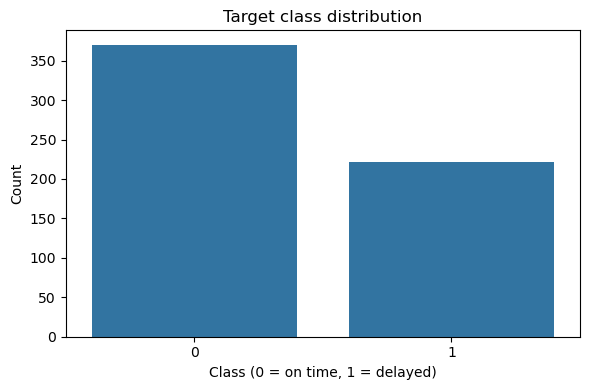

delayed
0    0.625
1    0.375
Name: proportion, dtype: float64


In [34]:
# Plot 1: target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=eda, x=target_col)                   # bar for each class
plt.title("Target class distribution")
plt.xlabel("Class (0 = on time, 1 = delayed)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(eda[target_col].value_counts(normalize=True).sort_index())   # class share

- About 62.5% deliveries are on time and 37.5% are delayed. There is some imbalance, so Accuracy alone can be misleading; we also use Precision, Recall, F1 and ROC-AUC.

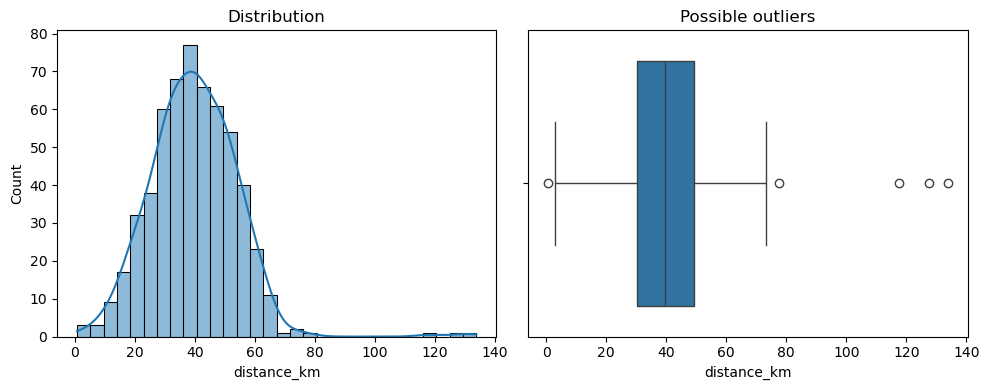

In [35]:
#  distribution and outliers of one numeric feature
numeric_feature = "distance_km"
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(eda[numeric_feature].dropna(), kde=True, ax=axes[0])   # histogram
sns.boxplot(x=eda[numeric_feature], ax=axes[1])                     # boxplot
axes[0].set_title("Distribution")
axes[1].set_title("Possible outliers")
plt.tight_layout()
plt.show()

- distance_km is roughly bell-shaped around 40 km, with a few very long deliveries (outliers, up to about 134 km). These are real but rare long trips.

## NUMERIC FEATURE VS TARGET

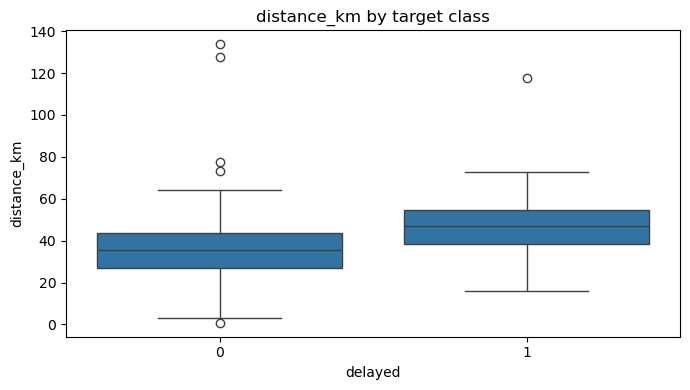

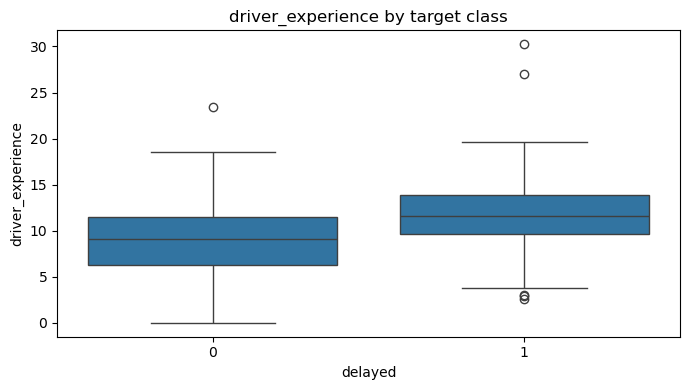

In [37]:
# numeric features vs target (bivariate)
for numeric_feature in ["distance_km", "driver_experience"]:   # two most related features
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=eda, x=target_col, y=numeric_feature)     # compare both classes
    plt.title(numeric_feature + " by target class")
    plt.tight_layout()
    plt.show()

- Distance: delayed deliveries have a clearly higher median distance - longer route means higher delay risk.
- Driver experience: delayed deliveries have a higher median experience. This is an unexpected pattern, but it is a clear difference, so the feature is useful for prediction.
Both are strong signals.

## CATAGORICAL FEATURES VS TARGET 

,count,mean
weather,,
b,192,0.427083
NaN,20,0.400000
c,181,0.359116
a,199,0.336683


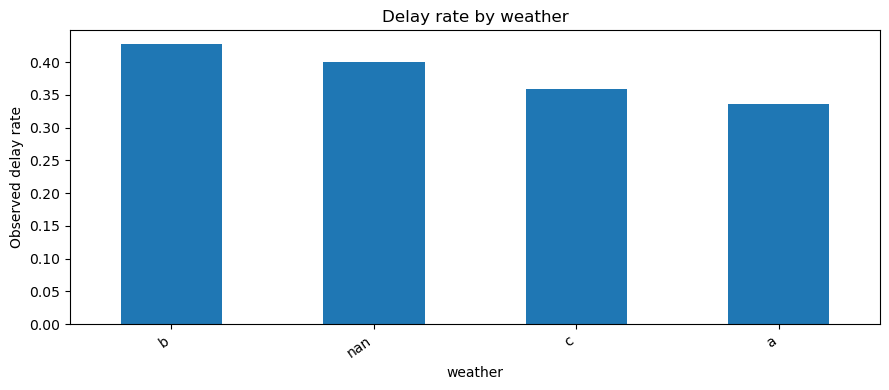

,count,mean
vehicle_type,,
NaN,20,0.500000
south,125,0.416000
west,152,0.401316
east,161,0.378882
north,134,0.283582


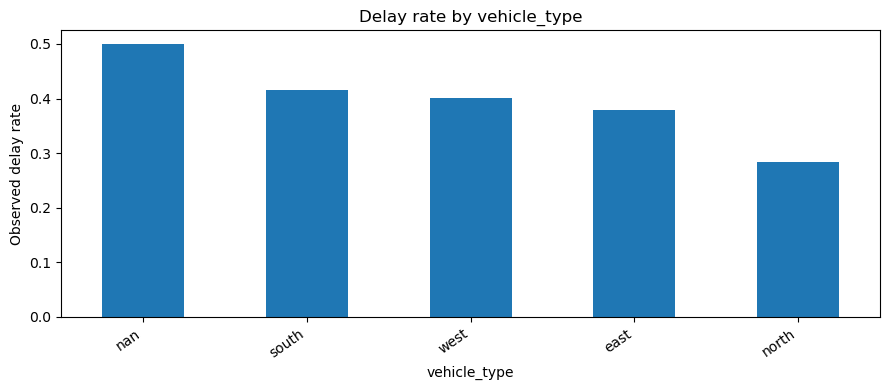

In [38]:
# Plot 4: categorical feature vs target (delay rate per category)
for category_feature in ["weather", "vehicle_type"]:
    rate = eda.groupby(category_feature, dropna=False)[target_col].agg(
        ["count", "mean"]).sort_values("mean", ascending=False)    # count and delay rate
    display(rate)

    rate["mean"].head(12).plot(kind="bar", figsize=(9, 4))
    plt.ylabel("Observed delay rate")
    plt.title("Delay rate by " + category_feature)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

- Weather: category b has the highest delay rate (about 43%), c about 36% and a about 34%.
- Vehicle type: south (about 42%) and west (about 40%) have higher delay rates; north has the lowest (about 28%).
- The differences are small to medium, so these features help a little.

# MULTIVARIATE


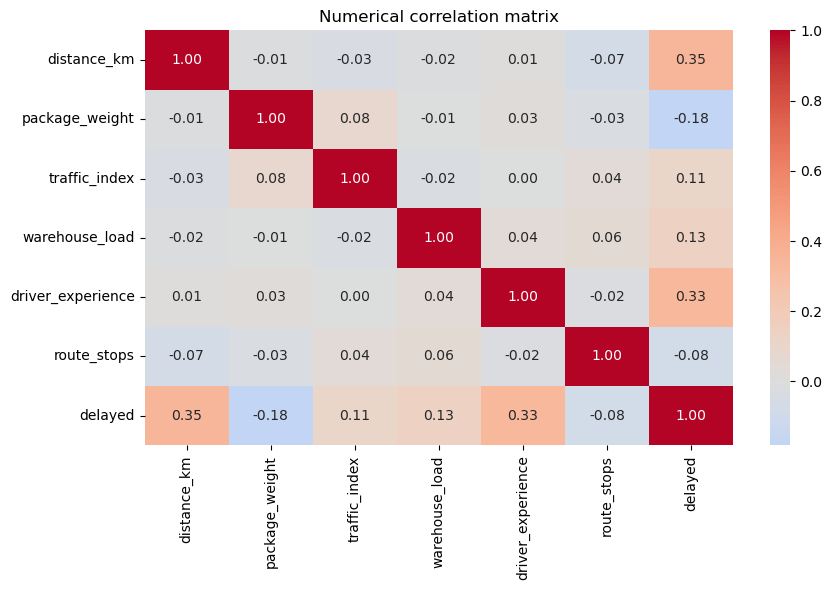

In [40]:
# correlation heatmap (multivariate)
numeric_for_corr = eda.select_dtypes(include=np.number)
plt.figure(figsize=(9, 6))
sns.heatmap(numeric_for_corr.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Numerical correlation matrix")
plt.tight_layout()
plt.show()

- The features are almost not correlated with each other (values near 0), so there is no multicollinearity problem. 
- Distance and driver experience have the strongest positive correlation with delayed (about 0.35), package_weight is negative (about -0.16), while traffic_index and warehouse_load are weakly positive (about 0.12).

# Missing values, scatter plot, weather vs target


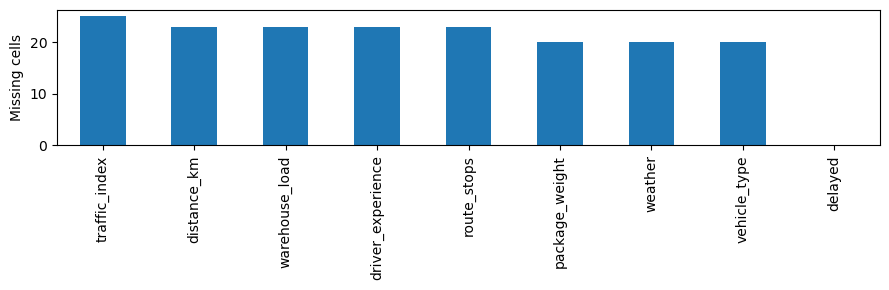

In [47]:
# missing values per column
eda.isna().sum().sort_values(ascending=False).head(15).plot(kind="bar", figsize=(9, 3))
plt.ylabel("Missing cells")
plt.tight_layout()
plt.show()




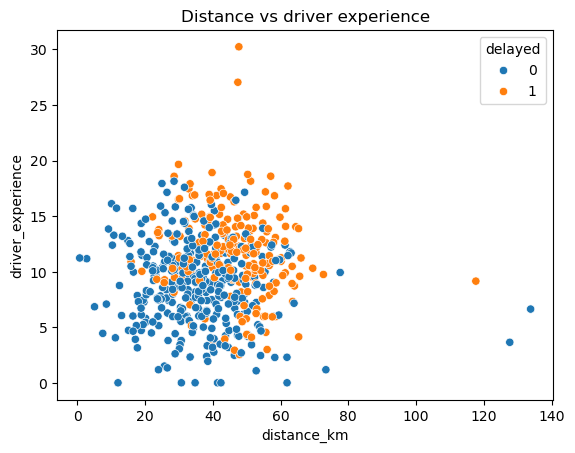

In [43]:
#  multivariate scatter (two numeric features, coloured by target)
sns.scatterplot(data=eda, x="distance_km", y="driver_experience", hue=target_col)
plt.title("Distance vs driver experience")
plt.show()

- Missing values: every column has a similar small number (about 20-25), so they look random. Median / most-frequent filling is fine.
- Scatter plot: delayed deliveries (class 1) appear more at longer distance and higher experience, but the two classes overlap a lot

# PREPROCESSING

In [51]:
# fill missing values, encode text, scale only when needed
def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]     # fill numbers with median
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))              # scale if model needs it

    numeric_pipe = Pipeline(numeric_steps)
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),           # fill text with most common
        ("encoder", OneHotEncoder(handle_unknown="ignore"))             # text -> 0/1 columns
    ])
    return ColumnTransformer([
        ("numbers", numeric_pipe, numeric_columns),
        ("categories", categorical_pipe, categorical_columns)
    ], remainder="drop")

# Baseline pipeline: Logistic Regression, fitted on TRAIN only
baseline = Pipeline([
    ("prep", make_preprocessor(scale_numeric=True)),
    ("model", LogisticRegression(max_iter=1500, random_state=42))
])
baseline.fit(X_train, y_train)                          # learn from training data only

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('numbers',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['distance_km',
                                                   'package_weight',
                                                   'traffic_index',
                                                   'warehouse_load',
                                                   'driver_experience',
                                                   'route_stops']),
                                                 ('categories',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['weather',
                                                   'vehicle_type'])])),
                ('model', LogisticRegression(max_iter=1500, random_state=42))])

- The preprocessing fills missing numbers with the median and missing categories with the most frequent value, then one-hot encodes the text columns.
- Scaling is used only when needed (Logistic Regression, KNN, SVM). Trees do not need it.
- Everything is inside a Pipeline, fitted on training data only, so there is no preprocessing leakage.


# BUILDS MODELS

In [52]:
# Dictionary of models
models = {
    "Logistic Regression": Pipeline([
        ("prep", make_preprocessor(True)),
        ("model", LogisticRegression(max_iter=1500, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("prep", make_preprocessor(False)),
        ("model", DecisionTreeClassifier(max_depth=6, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("prep", make_preprocessor(False)),
        ("model", RandomForestClassifier(n_estimators=150, random_state=42))
    ]),
    "KNN": Pipeline([
        ("prep", make_preprocessor(True)),
        ("model", KNeighborsClassifier(n_neighbors=7))
    ]),
    "SVM": Pipeline([
        ("prep", make_preprocessor(True)),
        ("model", SVC(kernel="rbf", C=1.0, random_state=42))
    ])
}
print("Models:", list(models.keys()))

Models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVM']


# CROSS VALIDATAION AND MODEL COMPARISON 

In [53]:
# Stratified 5-fold cross-validation for all models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scoring = {"accuracy": "accuracy", "precision": "precision",
              "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

rows = []
for name, pipe in models.items():                       # loop over all models
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=cv_scoring, error_score="raise")
    rows.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

comparison = pd.DataFrame(rows).sort_values("CV F1", ascending=False)
display(comparison.round(3))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
4,SVM,0.775,0.724,0.648,0.682,0.841
0,Logistic Regression,0.774,0.731,0.639,0.678,0.841
2,Random Forest,0.757,0.711,0.589,0.640,0.825
1,Decision Tree,0.701,0.610,0.572,0.587,0.718
3,KNN,0.704,0.639,0.505,0.561,0.758


- SVM (F1 0.682) and Logistic Regression (F1 0.678) are the best, with ROC-AUC about 0.84.
- Random Forest (F1 0.640) is next, then Decision Tree (0.587) and KNN (0.561).
- Recall is lower than precision for all models, which means the models miss some delayed deliveries

# TRAIN VS CV SCORE (OVERFIT OR UNDERFIT CHECK)

In [54]:
# Train score vs CV score (to check overfitting)
for name, model in models.items():
    model.fit(X_train, y_train)                                          # fit on training data
    train_f1 = f1_score(y_train, model.predict(X_train), zero_division=0)  # score on training data
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1").mean()  # score on unseen folds
    print(name, "Train F1:", round(train_f1, 3), "CV F1:", round(cv_f1, 3))

Logistic Regression Train F1: 0.697 CV F1: 0.678
Decision Tree Train F1: 0.812 CV F1: 0.587
Random Forest Train F1: 1.0 CV F1: 0.64
KNN Train F1: 0.696 CV F1: 0.561
SVM Train F1: 0.779 CV F1: 0.682


- Random Forest: train F1 = 1.00 but CV F1 = 0.64 -> strong overfitting (it memorised the training data).
- Decision Tree: 0.81 vs 0.59 -> overfitting.
- KNN: 0.70 vs 0.56 -> some overfitting.
- Logistic Regression (0.697 vs 0.678) and SVM (0.779 vs 0.682) have a small gap, so they  better.
- No model shows underfitting. The highest training score (Random Forest, 1.00) is not the best model. 

In [55]:
# Hyperparameter tuning of Random Forest with GridSearchCV
rf_pipe = Pipeline([
    ("prep", make_preprocessor(False)),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200],         # number of trees
    "model__max_depth": [None, 5, 10],         # maximum depth of each tree
    "model__min_samples_leaf": [1, 3]          # minimum samples in a leaf
}

search = GridSearchCV(estimator=rf_pipe, param_grid=param_grid,
                      scoring="f1", cv=cv, n_jobs=-1)
search.fit(X_train, y_train)                   # try all combinations
print("Best parameters:", search.best_params_)
print("Best cross-validated F1:", round(search.best_score_, 3))

best_rf = search.best_estimator_               # best Random Forest found

Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best cross-validated F1: 0.651


- Best settings: n_estimators = 200, max_depth = 10, min_samples_leaf = 1; best CV F1 = 0.651.
- Tuning improved Random Forest a little (0.640 -> 0.651), but it is still below Logistic Regression and SVM.

# SELECT THE FINAL MODEL 

In [58]:
# Choose the final model using CROSS-VALIDATION scores only (not test scores)
tuned_row = pd.DataFrame([{"Model": "Tuned Random Forest",
                           "CV F1": search.best_score_}])          # CV F1 of tuned forest
selection = pd.concat([comparison[["Model", "CV F1"]], tuned_row])  # add it to earlier results
display(selection.sort_values("CV F1", ascending=False).round(3))

# Logistic Regression: simple, stable (small train-CV gap) and gives probabilities
final_model = models["Logistic Regression"]        # selected final classifier
final_model.fit(X_train, y_train)                  # fit on training data only
print("Final model selected: Logistic Regression")

,Model,CV F1
4,SVM,0.682
0,Logistic Regression,0.678
0,Tuned Random Forest,0.651
2,Random Forest,0.640
1,Decision Tree,0.587
3,KNN,0.561


Final model selected: Logistic Regression


- By cross-validated F1: SVM 0.682, Logistic Regression 0.678, Tuned Random Forest 0.651.
- SVM and Logistic Regression are almost equal. We select Logistic Regression because it is simple, has a small train-CV gap, gives real probabilities (needed for the threshold bonus) and is easy to explain.

# CONFUSION MATRIX

Confusion matrix [0,1]:
 [[83  9]
 [18 38]]
TN, FP, FN, TP: [83  9 18 38]


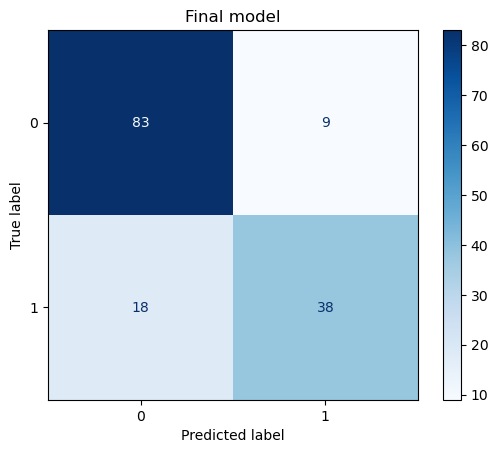

In [77]:
# Final evaluation on the untouched test set
y_pred = final_model.predict(X_test)           # predicted classes

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion matrix [0,1]:\n", cm)
print("TN, FP, FN, TP:", cm.ravel())
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1], cmap="Blues")
plt.title("Final model")
plt.show()

- False Positive here = we warn about a delay that does not happen:  an unnecessary alert to the customer.

- False Negative here = a real delay is missed: the customer is not warned, which leads to unhappy customers and penalties. so Recall matters.

In [80]:
# Reusable function 3: evaluate any fitted classifier on given data
def evaluate_classifier(model, features, truth):
    pred = model.predict(features)                                  # predicted class 0/1
    row = {
        "Accuracy": accuracy_score(truth, pred),                    # overall correct share
        "Precision": precision_score(truth, pred, zero_division=0), # of predicted delayed, how many truly delayed
        "Recall": recall_score(truth, pred, zero_division=0),       # of truly delayed, how many we caught
        "F1": f1_score(truth, pred, zero_division=0)                # balance of precision and recall
    }
    if hasattr(model, "predict_proba"):                             # model gives probabilities
        score = model.predict_proba(features)[:, 1]
    elif hasattr(model, "decision_function"):                       # model gives decision scores
        score = model.decision_function(features)
    else:
        score = None
    row["ROC-AUC"] = (roc_auc_score(truth, score)
                      if score is not None and truth.nunique() == 2
                      else np.nan)                                  # ROC-AUC needs scores, not 0/1
    return row

print("Functions created")

Functions created


In [78]:
# All final metrics using our function
result = evaluate_classifier(final_model, X_test, y_test)
print(pd.Series(result).round(3))
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

Accuracy     0.818
Precision    0.809
Recall       0.679
F1           0.738
ROC-AUC      0.881
dtype: float64
              precision    recall  f1-score   support

           0       0.82      0.90      0.86        92
           1       0.81      0.68      0.74        56

    accuracy                           0.82       148
   macro avg       0.82      0.79      0.80       148
weighted avg       0.82      0.82      0.81       148



- Accuracy = 0.818, Precision = 0.809, Recall = 0.679, F1 = 0.738, ROC-AUC = 0.881.
- The test scores are close to (or a bit better than) the CV scores, so the model is not overfitted.
- **Why Accuracy alone is misleading:**  62% of deliveries are on time, so a model that always says 'on time' would already get about 62% accuracy while catching zero delays. Precision, Recall, F1 and ROC-AUC show the real quality

# ROC CURVE

First 10 probabilities: [0.508 0.387 0.347 0.543 0.285 0.471 0.44  0.166 0.127 0.172]


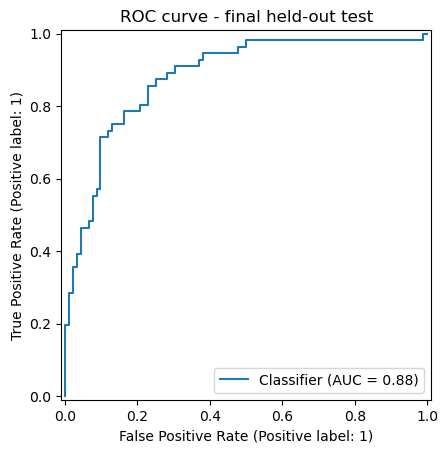

PR-AUC (average precision): 0.825


In [75]:
# ROC curve, predicted probabilities and PR-AUC
probs = final_model.predict_proba(X_test)[:, 1]            # probability of delayed
print("First 10 probabilities:", probs[:10].round(3))
RocCurveDisplay.from_predictions(y_test, probs)
plt.title("ROC curve - final held-out test")
plt.show()
print("PR-AUC (average precision):", round(average_precision_score(y_test, probs), 3))

# FINAL CONCLUSION 